# 02 · Prediction + Nsight Systems analysis

**Goal:** predict decode performance from first principles, then use the nsys traces to explain every millisecond of a decode step, and finish with a ranked list of kernels (plus ready-to-run commands) for the Nsight Compute session.

| Part | What it does | Needs GPU? |
|---|---|---|
| **A. Prediction** | Hardware peaks, exact weight inventory from the model's `config.json`, decode floor, batch-scaling model | No |
| **B. Baseline** | Table 1: predicted vs measured latency from the `vllm bench latency` JSONs | No |
| **C. nsys analysis** | Phase split, GPU busy %, step times, kernel attribution, achieved bandwidth per GEMM, roofline, step reconciliation, graphs vs eager | No |
| **D. ncu plan** | Ranks kernels by *time lost vs their roofline* and writes `runs/<id>/ncu_plan/ncu_commands.sh`, which notebook 01 runs on the VM | No |

**Input:** one run folder produced by notebook 01 (or the included `runs/2026-10-09_qwen3.8-27b_bf16_initial`):
```
runs/<run_id>/config.json         settings the run used (vLLM args, sweep, nsys config)
runs/<run_id>/bench/lat_b{B}_in{L}_out{O}.json
runs/<run_id>/nsys/b{B}_{graphs|eager}.sqlite
```
**Output:** `runs/<run_id>/analysis/` (figures, CSV tables, `findings.md`) and `runs/<run_id>/ncu_plan/`.

> Conventions: **measured** numbers come from your files; **predicted** numbers come from the model in Part A; anything inferred is labeled as such.

## 0. Configuration

In [1]:
import json, os, re
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
# Which run to analyze: set RUN_ID, or leave None to pick the newest run folder.
# (Notebook 01 passes RUN_DIR through the environment when it runs this notebook for you.)
RUN_ID = None
if os.environ.get("RUN_DIR"):
    RUN_DIR = Path(os.environ["RUN_DIR"])
elif RUN_ID:
    RUN_DIR = REPO / "runs" / RUN_ID
else:
    RUN_DIR = sorted([p for p in (REPO / "runs").iterdir() if (p / "config.json").exists()])[-1]
RUN_CFG = json.loads((RUN_DIR / "config.json").read_text())
print("Analyzing run:", RUN_DIR.name)

TRACE_DIR = RUN_DIR / "nsys"
BASELINE_DIR = RUN_DIR / "bench"
OUT_DIR = RUN_DIR / "analysis"; OUT_DIR.mkdir(exist_ok=True)
NCU_DIR = RUN_DIR / "ncu_plan"; NCU_DIR.mkdir(exist_ok=True)
ROOT = RUN_DIR                           # figure paths are printed relative to the run folder

MODEL_ID = RUN_CFG["vllm"]["model"]
DTYPE_BYTES = 2                          # BF16 weights / activations (change for an FP8 checkpoint)
INPUT_LEN = RUN_CFG["workload"]["input_len"]

# nsys captures present in the run: name -> (sqlite file, batch size, mode)
TRACES = {}
for B in RUN_CFG["nsys"]["batch_sizes"]:
    for mode in RUN_CFG["nsys"]["modes"]:
        TRACES[f"b{B}_{mode}"] = (f"b{B}_{mode}.sqlite", B, mode)
DECODE_RANGE_PREFIX = "prefill_decode"   # NVTX range = prefill + OUT decode steps
PREFILL_RANGE_PREFIX = "prefill_b"       # NVTX range = prefill only (max_tokens=1)
OUT_TOKENS = RUN_CFG["nsys"]["out_tokens"]   # forward passes in the decode range

# Baseline sweep (vllm bench latency)
BENCH_BATCHES = RUN_CFG["bench"]["batch_sizes"]
BENCH_OUT = max(RUN_CFG["bench"]["output_lens"])

# Hardware peaks, derived from what notebook 01 recorded on the VM (runs/<id>/env/env.json, step 5):
#   HBM bandwidth       = 2 (DDR) x max memory clock x memory bus width / 8
#   dense tensor FLOP/s = SMs x tensor clock x tensor FLOP/clk/SM
# FLOP/clk/SM is an architecture constant (the driver does not report it), keyed by compute capability.
# Tensor clock: NVIDIA quotes low-precision tensor peaks at a lower clock than the max boost the driver
# reports (H100 SXM: 1.83 GHz vs 1.98 GHz max; 132 x 4096 x 1.83 GHz = 989 TFLOP/s). Where such a clock
# is listed below it is used; otherwise the driver's max SM clock.
BF16_FLOP_PER_CLK_SM = {(8, 0): 2048, (8, 6): 1024, (8, 9): 1024, (9, 0): 4096, (10, 0): 8192}   # dense
TENSOR_CLOCK_GHZ = {(9, 0): 1.83}
FP8_PER_BF16 = {(8, 9): 2, (9, 0): 2, (10, 0): 2}
ENV_JSON = RUN_DIR / "env" / "env.json"
ENV = json.loads(ENV_JSON.read_text()) if ENV_JSON.exists() else {}
GPU = ENV.get("gpu_attrs", {})
if "sm_count" in GPU:
    cc = (GPU["cc_major"], GPU["cc_minor"])
    if cc not in BF16_FLOP_PER_CLK_SM:
        raise KeyError(f"add the dense BF16 tensor FLOP/clk/SM for compute capability {cc} to BF16_FLOP_PER_CLK_SM")
    tensor_ghz = TENSOR_CLOCK_GHZ.get(cc, GPU["sm_clock_max_khz"] / 1e6)
    bf16 = GPU["sm_count"] * tensor_ghz * 1e9 * BF16_FLOP_PER_CLK_SM[cc] / 1e12
    HW = dict(
        name=ENV["gpu"].split(",")[0].strip(),
        hbm_bw_TBps=2 * GPU["mem_clock_max_khz"] * 1e3 * GPU["mem_bus_width_bits"] / 8 / 1e12,
        bf16_tflops=bf16,
        fp8_tflops=bf16 * FP8_PER_BF16.get(cc, 1),
        sms=GPU["sm_count"],
        tensor_clock_GHz=tensor_ghz,
        l2_MB=GPU["l2_bytes"] / 2**20,
        source="measured: env/env.json",
    )
else:  # runs captured before env_capture recorded gpu_attrs (e.g. the initial 2026-10-09 run)
    HW = dict(name="H100 SXM5 80GB", hbm_bw_TBps=3.35, bf16_tflops=989.0, fp8_tflops=1979.0, sms=132, l2_MB=50,
              tensor_clock_GHz=1.83,
              source="DATASHEET FALLBACK: this run has no env/env.json gpu_attrs (notebook 01 step 5)")
HW["realistic_bw_frac"] = 0.92          # assumption: best streaming kernels reach ~90-93% of peak bandwidth
print(f"{HW['name']}: {HW['hbm_bw_TBps']:.2f} TB/s HBM, {HW['bf16_tflops']:.0f} BF16 TFLOP/s "
      f"(@ {HW['tensor_clock_GHz']:.2f} GHz), "
      f"{HW['sms']} SMs, {HW['l2_MB']:.0f} MB L2   [{HW['source']}]")

# Weights resident on the GPU, from this run's vLLM logs: "Model loading took X GiB memory"
loaded = sorted({float(m) for f in (RUN_DIR / "logs").glob("*.log")
                 for m in re.findall(r"Model loading took ([\d.]+) GiB", f.read_text(errors="replace"))})
if not loaded:
    raise FileNotFoundError(f"no 'Model loading took' line in {RUN_DIR / 'logs'}/*.log (pulled by notebook 01 step 9)")
if len(loaded) > 1:
    print(f"WARNING: logs disagree on the loaded weights {loaded} GiB; using the largest")
LOADED_WEIGHTS_GIB = loaded[-1]
print(f"Loaded weights: {LOADED_WEIGHTS_GIB} GiB   [measured: logs/*.log]")

Analyzing run: 2026-10-09_qwen3.8-27b_bf16_initial
H100 SXM5 80GB: 3.35 TB/s HBM, 989 BF16 TFLOP/s (@ 1.83 GHz), 132 SMs, 50 MB L2   [DATASHEET FALLBACK: this run has no env/env.json gpu_attrs (notebook 01 step 5)]
Loaded weights: 50.22 GiB   [measured: logs/*.log]


## 1. Imports and helpers

In [2]:
import json, re, sqlite3, math, subprocess, shutil, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

PEAK_BW = HW["hbm_bw_TBps"] * 1e12      # bytes/s
PEAK_FLOPS = HW["bf16_tflops"] * 1e12   # FLOP/s
RIDGE = PEAK_FLOPS / PEAK_BW            # FLOP/byte

def savefig(name):
    p = OUT_DIR / f"{name}.png"; plt.savefig(p, bbox_inches="tight"); print(f"saved {p.relative_to(ROOT)}")

def ms(ns): return ns / 1e6

# Part A. Prediction (before looking at any trace)

## A1. Model shapes from `config.json`
Downloaded once and cached. Every GEMM shape below is derived from the config; vLLM fuses some projections (gate+up, q+k+v, GDN qkv+z, GDN b+a), so we model the fused shapes, which is what the kernels actually read.

In [3]:
cfg_path = OUT_DIR / "model_config.json"
if not cfg_path.exists():
    url = f"https://huggingface.co/{MODEL_ID}/raw/main/config.json"
    cfg_path.write_bytes(urllib.request.urlopen(url, timeout=30).read())
full_cfg = json.loads(cfg_path.read_text())
C = full_cfg.get("text_config", full_cfg)

H   = C["hidden_size"]
I   = C["intermediate_size"]
V   = C["vocab_size"]
L   = C["num_hidden_layers"]
layer_types = C.get("layer_types") or ["full_attention"] * L
L_full = layer_types.count("full_attention"); L_lin = layer_types.count("linear_attention")
n_h, n_kv, hd = C["num_attention_heads"], C["num_key_value_heads"], C["head_dim"]
gate = 2 if C.get("attn_output_gate") else 1          # q_proj also produces the output gate
lk_h, lv_h = C["linear_num_key_heads"], C["linear_num_value_heads"]
lk_d, lv_d = C["linear_key_head_dim"], C["linear_value_head_dim"]
conv_k = C["linear_conv_kernel_dim"]
ssm_bytes = 4 if C.get("mamba_ssm_dtype", "float32") == "float32" else 2
tied = full_cfg.get("tie_word_embeddings", C.get("tie_word_embeddings", False))

print(f"hidden={H}  intermediate={I}  vocab={V}  layers={L} ({L_lin} GDN linear-attention + {L_full} full-attention)")
print(f"full attn: {n_h} q heads (x{gate} with output gate), {n_kv} kv heads, head_dim {hd}")
print(f"GDN: {lk_h} key heads x {lk_d}, {lv_h} value heads x {lv_d}, conv kernel {conv_k}, state dtype {ssm_bytes*8}-bit")
print(f"tie_word_embeddings = {tied}  -> input embedding table {'IS' if tied else 'is NOT'} the LM head")

hidden=5120  intermediate=17408  vocab=248320  layers=64 (48 GDN linear-attention + 16 full-attention)
full attn: 24 q heads (x2 with output gate), 4 kv heads, head_dim 256
GDN: 16 key heads x 128, 48 value heads x 128, conv kernel 4, state dtype 32-bit
tie_word_embeddings = False  -> input embedding table is NOT the LM head


In [4]:
# One row per fused GEMM that runs every forward pass: (name, count per forward, N_out, K_in)
qkv_out  = n_h * hd * gate + 2 * n_kv * hd
gdn_qkvz = 2 * lk_h * lk_d + lv_h * lv_d + lv_h * lv_d    # q + k + v + z
gdn_ba   = 2 * lv_h                                       # b + a (one scalar per value head each)
gemms = pd.DataFrame([
    ("mlp.gate_up",        L,      2 * I,      H),
    ("mlp.down",           L,      H,          I),
    ("gdn.in_proj_qkvz",   L_lin,  gdn_qkvz,   H),
    ("gdn.in_proj_ba",     L_lin,  gdn_ba,     H),
    ("gdn.out_proj",       L_lin,  H,          lv_h * lv_d),
    ("attn.qkv(+gate)",    L_full, qkv_out,    H),
    ("attn.o_proj",        L_full, H,          n_h * hd),
    ("lm_head",            1,      V,          H),
], columns=["gemm", "per_fwd", "N", "K"])
gemms["MB_each"] = gemms.N * gemms.K * DTYPE_BYTES / 1e6
gemms["MB_per_fwd"] = gemms.MB_each * gemms.per_fwd
gemms["share_%"] = 100 * gemms.MB_per_fwd / gemms.MB_per_fwd.sum()

GEMM_BYTES_PER_FWD = gemms.MB_per_fwd.sum() * 1e6
embed_bytes = 0 if tied else V * H * DTYPE_BYTES
print(f"Bytes read by GEMMs per forward pass: {GEMM_BYTES_PER_FWD/1e9:.2f} GB")
print(f"Input embedding table (read 1 row per token, not streamed): {embed_bytes/1e9:.2f} GB")
print(f"GEMM weights + embedding = {(GEMM_BYTES_PER_FWD+embed_bytes)/2**30:.2f} GiB   vs vLLM 'Model loading took' = {LOADED_WEIGHTS_GIB} GiB")
gemms.round(1)

Bytes read by GEMMs per forward pass: 51.24 GB
Input embedding table (read 1 row per token, not streamed): 2.54 GB
GEMM weights + embedding = 50.09 GiB   vs vLLM 'Model loading took' = 50.22 GiB


,gemm,per_fwd,N,K,MB_each,MB_per_fwd,share_%
0,mlp.gate_up,64,34816,5120,356.5,22817.0,44.5
1,mlp.down,64,5120,17408,178.3,11408.5,22.3
2,gdn.in_proj_qkvz,48,16384,5120,167.8,8053.1,15.7
3,gdn.in_proj_ba,48,96,5120,1.0,47.2,0.1
4,gdn.out_proj,48,5120,6144,62.9,3019.9,5.9
5,attn.qkv(+gate),16,14336,5120,146.8,2348.8,4.6
6,attn.o_proj,16,5120,6144,62.9,1006.6,2.0
7,lm_head,1,248320,5120,2542.8,2542.8,5.0


## A2. Per-sequence state that decode must also read
* **GDN recurrent state** (48 layers): a `value_heads x key_dim x value_dim` matrix per layer, kept in FP32, read **and** written every decode step. This grows with **batch**, not with context.
* **Full-attention KV cache** (16 layers): grows with **context** and batch.
* Conv state for the GDN short convolution is tiny.

In [5]:
gdn_state_per_seq = L_lin * lv_h * lk_d * lv_d * ssm_bytes                     # bytes
conv_state_per_seq = L_lin * (conv_k - 1) * (2 * lk_h * lk_d + lv_h * lv_d) * DTYPE_BYTES
kv_per_token = L_full * 2 * n_kv * hd * DTYPE_BYTES
print(f"GDN state per sequence : {gdn_state_per_seq/1e6:7.1f} MB  (read + write each step -> {2*gdn_state_per_seq/1e6:.0f} MB of traffic)")
print(f"Conv state per sequence: {conv_state_per_seq/1e6:7.2f} MB")
print(f"KV cache per token     : {kv_per_token/1e3:7.1f} KB  (only {L_full} of {L} layers keep a KV cache)")
print(f"KV read at ctx={INPUT_LEN+OUT_TOKENS}: {kv_per_token*(INPUT_LEN+OUT_TOKENS)/1e6:.1f} MB per sequence per step")

GDN state per sequence :   151.0 MB  (read + write each step -> 302 MB of traffic)
Conv state per sequence:    2.95 MB
KV cache per token     :    65.5 KB  (only 16 of 64 layers keep a KV cache)
KV read at ctx=576: 37.7 MB per sequence per step


## A3. Decode floor at batch 1
`T_step = max(compute, memory)`. At batch 1 every weight is read once per token, so memory wins by ~300x.

In [6]:
def decode_model(B, ctx, bw=PEAK_BW, flops=PEAK_FLOPS):
    # bytes and FLOPs for one decode step with B sequences at context length ctx
    w = GEMM_BYTES_PER_FWD
    state = B * (2 * gdn_state_per_seq + 2 * conv_state_per_seq)
    kv = B * kv_per_token * ctx
    act = B * gemms.eval("per_fwd * (N + K)").sum() * DTYPE_BYTES
    fl = 2 * B * (gemms.per_fwd * gemms.N * gemms.K).sum()
    t_mem, t_cmp = (w + state + kv + act) / bw, fl / flops
    return dict(B=B, weights_GB=w/1e9, state_GB=state/1e9, kv_GB=kv/1e9, act_GB=act/1e9,
                bytes_GB=(w+state+kv+act)/1e9, GFLOP=fl/1e9, t_mem_ms=t_mem*1e3, t_cmp_ms=t_cmp*1e3,
                t_ms=max(t_mem, t_cmp)*1e3, AI=fl/(w+state+kv+act), tok_s=B/max(t_mem, t_cmp))

ctx_mid = INPUT_LEN + BENCH_OUT // 2
p1 = decode_model(1, ctx_mid)
p1_real = decode_model(1, ctx_mid, bw=PEAK_BW * HW["realistic_bw_frac"])
naive = LOADED_WEIGHTS_GIB * 2**30 / PEAK_BW * 1e3
print(f"Naive floor (all loaded weights / 3.35 TB/s)           : {naive:6.2f} ms")
print(f"Refined floor (only bytes decode reads, at spec BW)   : {p1['t_ms']:6.2f} ms   compute side {p1['t_cmp_ms']:.3f} ms")
print(f"Refined, at a realistic {HW['realistic_bw_frac']:.0%} of spec bandwidth      : {p1_real['t_ms']:6.2f} ms")
print(f"Arithmetic intensity {p1['AI']:.2f} FLOP/byte vs ridge {RIDGE:.0f} -> deeply memory-bound")
PRED = dict(naive_ms=naive, floor_ms=p1["t_ms"], floor_real_ms=p1_real["t_ms"])

Naive floor (all loaded weights / 3.35 TB/s)           :  16.10 ms
Refined floor (only bytes decode reads, at spec BW)   :  15.40 ms   compute side 0.052 ms
Refined, at a realistic 92% of spec bandwidth      :  16.74 ms
Arithmetic intensity 0.99 FLOP/byte vs ridge 295 -> deeply memory-bound


## A4. Batch-scaling prediction
Weights are shared across the batch, but GDN state and KV traffic scale with batch. The **interesting prediction for this hybrid model:** the per-sequence GDN state (~150 MB read+written per step) makes large-batch decode **state-bandwidth bound long before it becomes compute-bound**.

,B,weights_GB,state_GB,kv_GB,bytes_GB,GFLOP,AI,t_mem_ms,t_cmp_ms,t_ms,tok_s
0,1,51.24,0.31,0.04,51.60,51.24,0.99,15.40,0.05,15.40,64.92
1,8,51.24,2.46,0.30,54.11,409.95,7.58,16.15,0.41,16.15,495.25
2,32,51.24,9.85,1.21,62.72,1639.81,26.14,18.72,1.66,18.72,1709.06
3,64,51.24,19.70,2.42,74.21,3279.61,44.20,22.15,3.32,22.15,2889.29
4,128,51.24,39.41,4.83,97.17,6559.22,67.51,29.00,6.63,29.00,4413.05
5,256,51.24,78.82,9.66,143.09,13118.44,91.68,42.71,13.26,42.71,5993.49


saved analysis/A4_batch_scaling_prediction.png


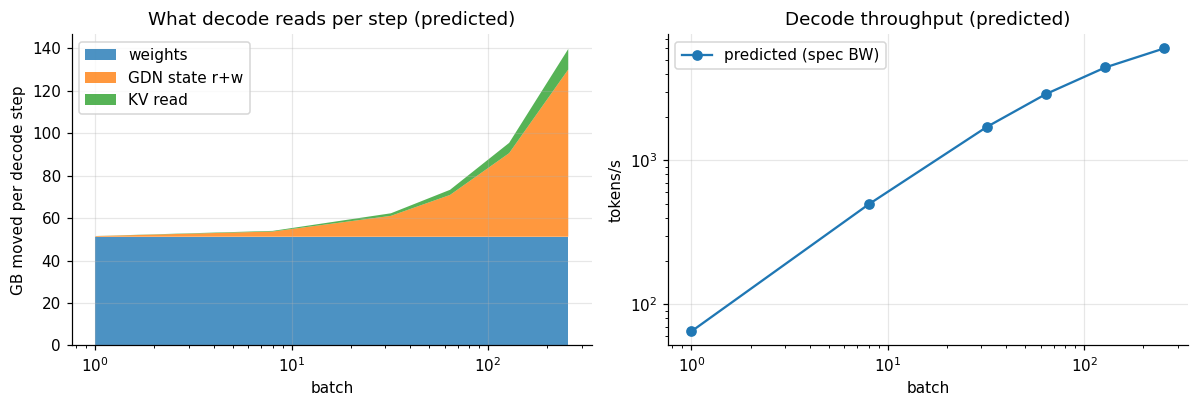

In [7]:
pred = pd.DataFrame([decode_model(B, ctx_mid) for B in BENCH_BATCHES])
display(pred[["B","weights_GB","state_GB","kv_GB","bytes_GB","GFLOP","AI","t_mem_ms","t_cmp_ms","t_ms","tok_s"]].round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].stackplot(pred.B, pred.weights_GB, pred.state_GB, pred.kv_GB, labels=["weights", "GDN state r+w", "KV read"], alpha=.8)
ax[0].set(xscale="log", xlabel="batch", ylabel="GB moved per decode step", title="What decode reads per step (predicted)"); ax[0].legend(loc="upper left")
ax[1].plot(pred.B, pred.tok_s, "o-", label="predicted (spec BW)")
ax[1].set(xscale="log", yscale="log", xlabel="batch", ylabel="tokens/s", title="Decode throughput (predicted)"); ax[1].legend()
plt.tight_layout(); savefig("A4_batch_scaling_prediction"); plt.show()

# Part B. Baseline benchmarks: Table 1 (predicted vs measured)

In [8]:
rows = []
for B in BENCH_BATCHES:
    f1, f2 = BASELINE_DIR / f"lat_b{B}_in{INPUT_LEN}_out1.json", BASELINE_DIR / f"lat_b{B}_in{INPUT_LEN}_out{BENCH_OUT}.json"
    if not (f1.exists() and f2.exists()):
        rows.append(dict(B=B, note="missing")); continue
    p = json.loads(f1.read_text())["avg_latency"]; t = json.loads(f2.read_text())["avg_latency"]
    d = (t - p) / (BENCH_OUT - 1)
    m = decode_model(B, ctx_mid)
    rows.append(dict(B=B, prefill_ms=p*1e3, decode_ms_per_step=d*1e3, tok_s=B/d,
                     pred_ms=m["t_ms"], meas_over_pred=d*1e3/m["t_ms"],
                     eff_TBps=m["bytes_GB"]/d/1e3, pct_of_peak=100*m["bytes_GB"]/d/1e3/HW["hbm_bw_TBps"]))
table1 = pd.DataFrame(rows)
table1.to_csv(OUT_DIR / "table1_baseline.csv", index=False)
display(table1.round(2))
print("eff_TBps = predicted bytes per step / measured step time: the effective bandwidth if the model's byte count is right.")

,B,prefill_ms,decode_ms_per_step,tok_s,pred_ms,meas_over_pred,eff_TBps,pct_of_peak
0,1,54.33,20.55,48.66,15.40,1.33,2.51,74.95
1,8,351.00,21.94,364.59,16.15,1.36,2.47,73.62
2,32,1326.60,25.19,1270.30,18.72,1.35,2.49,74.33
3,64,2645.06,29.67,2156.95,22.15,1.34,2.50,74.65
4,128,5279.92,59.46,2152.55,29.00,2.05,1.63,48.78
5,256,10565.01,97.82,2617.09,42.71,2.29,1.46,43.67


eff_TBps = predicted bytes per step / measured step time: the effective bandwidth if the model's byte count is right.


saved analysis/B_table1.png


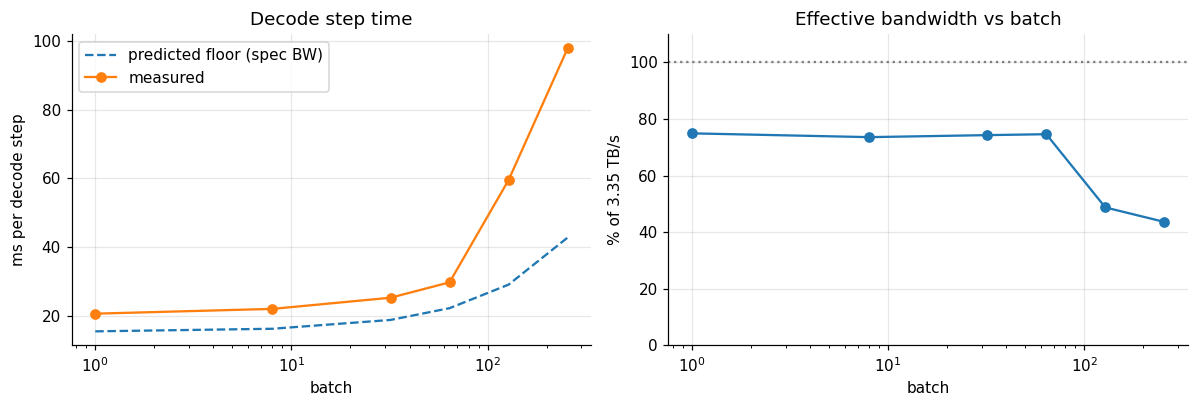

In [9]:
t1 = table1.dropna(subset=["decode_ms_per_step"]) if "decode_ms_per_step" in table1 else pd.DataFrame()
if len(t1):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(pred.B, pred.t_ms, "--", label="predicted floor (spec BW)")
    ax[0].plot(t1.B, t1.decode_ms_per_step, "o-", label="measured")
    ax[0].set(xscale="log", xlabel="batch", ylabel="ms per decode step", title="Decode step time"); ax[0].legend()
    ax[1].plot(t1.B, t1.pct_of_peak, "o-"); ax[1].axhline(100, color="gray", ls=":")
    ax[1].set(xscale="log", xlabel="batch", ylabel="% of 3.35 TB/s", title="Effective bandwidth vs batch", ylim=(0, 110))
    plt.tight_layout(); savefig("B_table1"); plt.show()
else:
    print("No baseline JSONs found in", BASELINE_DIR)

# Part C. Nsight Systems analysis
## C0. Trace loader
Reads the `.sqlite` that `nsys stats` created next to each report (CUPTI kernel table, NVTX ranges, CUDA runtime API calls). If a `.sqlite` is missing but the `nsys` CLI is installed, it exports one.

In [10]:
CATEGORIES = [   # (category, regex) -- first match wins; extend as new kernel families appear
    ("GDN conv",          r"causal_conv1d|post_conv"),
    ("GDN recurrent",     r"gated_delta|delta_rule|flashinfergdn|fused_recurrent|chunk_gated|chunk_fwd"),
    ("Full attention",    r"flash::|FlashAttn|flash_fwd|fmha|attention"),
    ("GEMM split-K reduce", r"splitKreduce|splitK_reduce"),
    ("GEMM",              r"nvjet|gemm|xmma|cublas|sm90_.*tst|cutlass.*Gemm"),
    ("RoPE / QK-norm",    r"rope|rotary|qk_rmsnorm"),
    ("Norm",              r"rms_norm|rmsnorm|layer_norm|MeanOps"),
    ("Activation",        r"silu|act_and_mul|gelu"),
    ("Sampling / logits", r"ArgMax|topk|top_k|sampling|softmax|scatter_gather|sampled|accepted|post_update"),
    ("KV cache write",    r"reshape_and_cache|kv_cache"),
    ("Copy / elementwise",r"copy|elementwise|Fill|index|CUDAFunctor|memcpy|batch_memcpy"),
]
GENERIC_SHORT_NAMES = {"device_kernel", "kernel", "Kernel", "kernel_cutlass_kernel"}

def categorize(name):
    for cat, rx in CATEGORIES:
        if re.search(rx, name, re.I): return cat
    return "Other"

def _q(con, sql):
    try: return pd.read_sql_query(sql, con)
    except Exception as e: return None

def ensure_sqlite(fname):
    p = TRACE_DIR / fname
    if p.exists(): return p
    rep = p.with_suffix(".nsys-rep")
    if rep.exists() and shutil.which("nsys"):
        subprocess.run(["nsys", "export", "--type", "sqlite", "--output", str(p), str(rep)], check=True)
        return p
    return None

def load_trace(fname):
    p = ensure_sqlite(fname)
    if p is None: return None
    if p.stat().st_size < 1024 and p.read_bytes().startswith(b"version https://git-lfs"):
        raise RuntimeError(f"{p.name} is a Git LFS pointer, not the trace. Run: brew install git-lfs && git lfs install && git lfs pull")
    con = sqlite3.connect(p)
    S = _q(con, "SELECT id, value FROM StringIds").set_index("id")["value"]
    k = _q(con, "SELECT * FROM CUPTI_ACTIVITY_KIND_KERNEL")
    name_col = "shortName" if "shortName" in k else "demangledName"
    k["short"] = k[name_col].map(S)
    k["full_name"] = k["demangledName"].map(S) if "demangledName" in k else k["short"]
    # CUTLASS/CuTe kernels share generic short names ("device_kernel"); name those by their signature instead
    generic = k["short"].isin(GENERIC_SHORT_NAMES)
    k["name"] = np.where(generic, k["full_name"].str.replace(r"^void ", "", regex=True).str.slice(0, 110), k["short"])
    k["dur"] = k["end"] - k["start"]
    k["cat"] = k["name"].map(categorize)
    k = k.sort_values("start").reset_index(drop=True)
    nv = _q(con, "SELECT start, end, text, textId FROM NVTX_EVENTS WHERE end IS NOT NULL")
    if nv is None: nv = _q(con, "SELECT start, end, text FROM NVTX_EVENTS WHERE end IS NOT NULL")
    if "textId" in nv: nv["text"] = nv["text"].fillna(nv["textId"].map(S))
    rt = _q(con, "SELECT start, end, nameId FROM CUPTI_ACTIVITY_KIND_RUNTIME")
    if rt is not None:
        rt["api"] = rt["nameId"].map(S).str.replace(r"_v\d+$", "", regex=True); rt["dur"] = rt["end"] - rt["start"]
    con.close()
    return dict(k=k, nvtx=nv, rt=rt)

def nvtx_range(tr, prefix):
    r = tr["nvtx"][tr["nvtx"].text.fillna("").str.startswith(prefix)]
    if r.empty: raise ValueError(f"No NVTX range starting with {prefix!r}; found {tr['nvtx'].text.unique()[:10]}")
    r = r.iloc[0]; return int(r.start), int(r.end)

def clip(k, s, e):
    return k[(k.end > s) & (k.start < e)]

def busy_ns(k, s, e):
    # union of kernel intervals clipped to [s, e] (handles overlapping streams correctly)
    iv = np.clip(k[["start", "end"]].to_numpy(), s, e)
    if len(iv) == 0: return 0, []
    iv = iv[np.argsort(iv[:, 0])]
    merged, gaps = [list(iv[0])], []
    for a, b in iv[1:]:
        if a <= merged[-1][1]: merged[-1][1] = max(merged[-1][1], b)
        else: gaps.append(a - merged[-1][1]); merged.append([a, b])
    return sum(b - a for a, b in merged), gaps

TR = {}
for key, (fname, B, mode) in TRACES.items():
    tr = load_trace(fname)
    if tr is None: print(f"[skip] {fname} not found"); continue
    tr.update(B=B, mode=mode); TR[key] = tr
    print(f"[ok]   {key:11s} {len(tr['k']):7d} kernels, {len(tr['nvtx'])} NVTX ranges, {0 if tr['rt'] is None else len(tr['rt'])} API calls")

[ok]   b1_graphs     59970 kernels, 2 NVTX ranges, 8763 API calls


[ok]   b1_eager     161500 kernels, 2 NVTX ranges, 331265 API calls


[ok]   b32_graphs    68720 kernels, 2 NVTX ranges, 11069 API calls


[ok]   b32_eager    170250 kernels, 2 NVTX ranges, 349205 API calls


## C1. Phase split: prefill, decode steps, GPU busy %
Decode steps are found from the **LM-head GEMM**: it is the last big kernel of every forward pass and runs exactly once per forward (= `OUT_TOKENS` times in the decode range). The time between consecutive LM-head ends is one decode step; the first one marks the end of prefill.

In [11]:
def find_lm_head(k, s, e, n_fwd):
    kk = clip(k, s, e)
    g = kk.groupby("name").agg(n=("dur", "size"), avg=("dur", "mean"))
    cand = g[(g.n >= n_fwd - 1) & (g.n <= n_fwd + 1) & g.index.str.contains(r"nvjet|gemm|xmma|cutlass", case=False)]
    if cand.empty: raise ValueError("LM head kernel not found; check OUT_TOKENS")
    return cand.avg.idxmax()

def analyze(tr):
    k = tr["k"]; s, e = nvtx_range(tr, DECODE_RANGE_PREFIX)
    lm = find_lm_head(k, s, e, OUT_TOKENS)
    ends = clip(k[k.name == lm], s, e).end.to_numpy()
    steps = np.diff(ends)                                    # one decode step each
    pre_s, pre_e = s, ends[0]
    busy_dec, gaps_dec = busy_ns(k, ends[0], ends[-1])
    busy_pre, gaps_pre = busy_ns(k, pre_s, pre_e)
    out = dict(lm_head=lm, range_ms=ms(e - s), prefill_wall_ms=ms(pre_e - pre_s), prefill_gpu_ms=ms(busy_pre),
               prefill_busy_pct=100 * busy_pre / (pre_e - pre_s),
               n_steps=len(steps), step_mean_ms=ms(steps.mean()), step_median_ms=ms(np.median(steps)),
               step_p90_ms=ms(np.percentile(steps, 90)), step_cv_pct=100 * steps.std() / steps.mean(),
               decode_busy_pct=100 * busy_dec / (ends[-1] - ends[0]),
               decode_idle_per_step_ms=ms((ends[-1] - ends[0] - busy_dec) / len(steps)))
    try:
        ps, pe = nvtx_range(tr, PREFILL_RANGE_PREFIX)
        b, _ = busy_ns(k, ps, pe); out.update(first_prefill_range_ms=ms(pe - ps), first_prefill_gpu_ms=ms(b))
    except ValueError: pass
    rt = tr["rt"]
    if rt is not None:
        r = clip(rt, ends[0], ends[-1])
        launches = r.api.str.contains("LaunchKernel", regex=True).sum()   # runtime API only; driver-API launches (Triton, FlashInfer) are in another table
        graphs = r.api.str.contains("GraphLaunch").sum()
        out.update(kernel_launches_per_step=launches / len(steps), graph_launches_per_step=graphs / len(steps))
    out["kernels_per_step"] = len(clip(k, ends[0], ends[-1])) / len(steps)
    tr.update(range=(s, e), lm_ends=ends, steps=steps, gaps_dec=np.array(gaps_dec), gaps_pre=np.array(gaps_pre))
    return out

PH = pd.DataFrame({key: analyze(tr) for key, tr in TR.items()}).T
PH.to_csv(OUT_DIR / "C1_phase_summary.csv")
display(PH.drop(columns=["lm_head"]).astype(float).round(2).T)
print("LM head kernel per trace:", PH.lm_head.to_dict())

,b1_graphs,b1_eager,b32_graphs,b32_eager
range_ms,1361.58,3935.14,2905.65,5616.00
prefill_wall_ms,54.89,93.05,1299.94,1525.06
prefill_gpu_ms,44.97,53.86,1279.24,1503.15
prefill_busy_pct,81.93,57.88,98.41,98.56
n_steps,63.00,63.00,63.00,63.00
step_mean_ms,20.72,60.98,25.46,64.92
step_median_ms,20.68,60.54,25.44,64.52
step_p90_ms,20.75,63.11,25.48,68.61
step_cv_pct,1.43,2.69,0.33,6.23
decode_busy_pct,97.40,38.37,97.80,45.34


LM head kernel per trace: {'b1_graphs': 'nvjet_sm90_tst_512x8_64x3_2x1_v_bz_TNT', 'b1_eager': 'nvjet_sm90_tst_512x8_64x3_2x1_v_bz_TNT', 'b32_graphs': 'nvjet_sm90_tst_384x32_64x4_2x1_v_bz_TNT', 'b32_eager': 'nvjet_sm90_tst_384x32_64x4_2x1_v_bz_TNT'}


saved analysis/C1_step_times.png


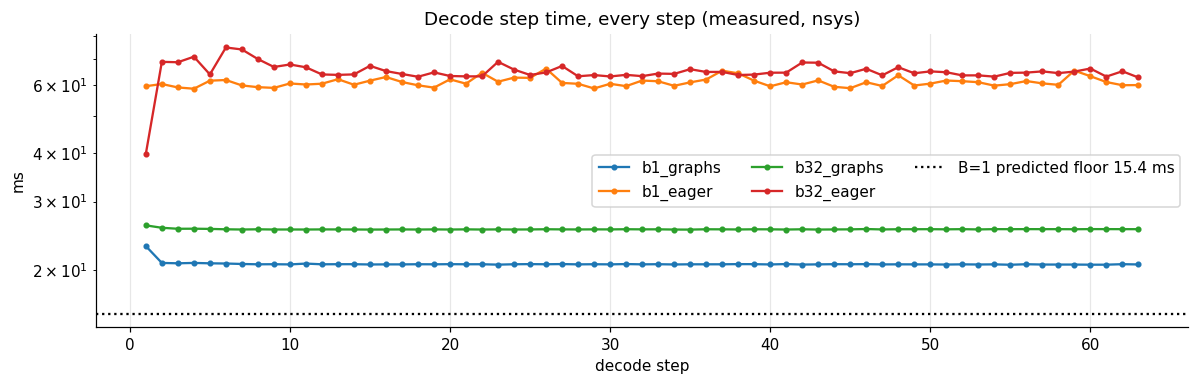

In [12]:
fig, ax = plt.subplots(figsize=(11, 3.6))
for key, tr in TR.items():
    ax.plot(np.arange(1, len(tr["steps"]) + 1), ms(tr["steps"]), ".-", label=key)
ax.axhline(PRED["floor_ms"], color="k", ls=":", label=f"B=1 predicted floor {PRED['floor_ms']:.1f} ms")
ax.set(yscale="log", xlabel="decode step", ylabel="ms", title="Decode step time, every step (measured, nsys)"); ax.legend(ncol=3)
plt.tight_layout(); savefig("C1_step_times"); plt.show()

## C2. Where the time goes: kernel categories, prefill vs decode
Per-step numbers use `instances / decode steps`, so they read directly as "per token" at batch 1.

b1_graphs         b1_eager         b32_graphs         b32_eager        
                      prefill  decode  prefill  decode    prefill  decode   prefill  decode
cat                                                                                        
GEMM                   33.911  18.698   34.362  18.859   1100.615  19.554  1071.572  19.714
Copy / elementwise      1.859   0.013   10.005   2.895     25.707   0.354   298.063   3.530
Activation              0.988   0.081    1.192   0.286     35.423   0.114    36.010   0.300
GDN conv                0.962   0.118    0.941   0.121     29.762   0.165    29.209   0.174
GDN recurrent           4.446   0.272    4.328   0.286     21.108   3.197    20.495   3.203
Norm                    1.289   0.458    0.293   0.083     37.793   0.492     9.646   0.117
Other                   0.291   0.080    1.558   0.365     10.238   0.135    20.051   1.505
RoPE / QK-norm          0.266   0.046    0.256   0.049      9.404   0.052     9.186   0.056
Full attention          0.846   0.185    0.822   0.226      7.613   0.570     7.386   0.585
KV cache write          0.081   0.032    0.074   0.036      1.628   0.036     1.588   0.038
GEMM split-K reduce     0.093   0.197    0.095   0.217      0.000   0.226     0.000   0.243
Sampling / logits       0.003   0.012    0.002   0.012      0.003   0.016     0.004   0.016

saved analysis/C2_categories.png


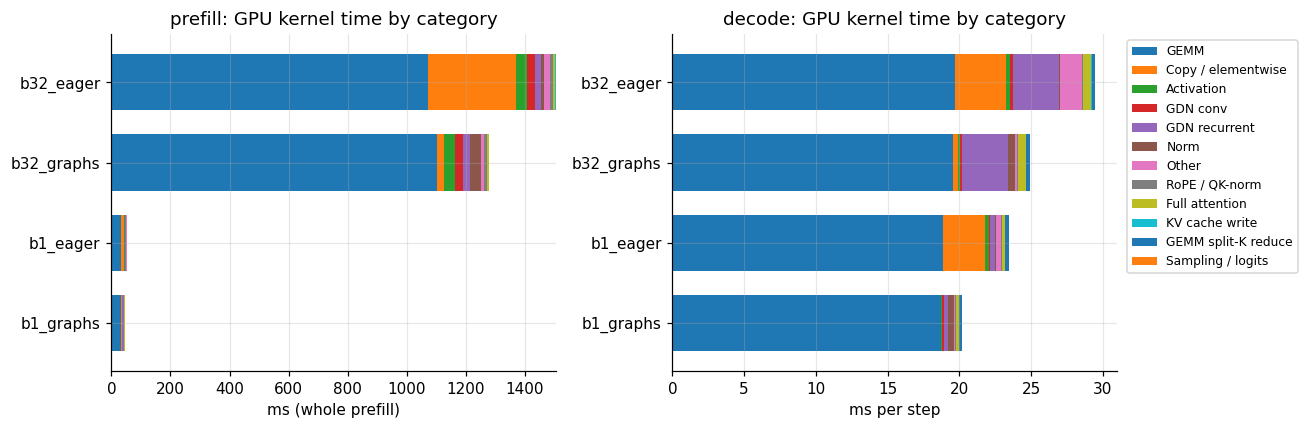

Top decode kernels (b1_graphs):


,cat,name,instances,avg_us,total_ms,per_step,ms_per_step,pct
0,GEMM,nvjet_sm90_tst_384x8_64x4_4x1_v_bz_TNT,4032,127.328,513.387,64.0,8.149,40.363
1,GEMM,nvjet_sm90_tst_128x8_64x12_4x1_v_bz_splitK_TNT,4032,64.645,260.648,64.0,4.137,20.492
2,GEMM,nvjet_sm90_tst_128x8_64x12_2x1_v_bz_TNT,3024,59.442,179.754,48.0,2.853,14.132
3,GEMM,nvjet_sm90_tst_64x8_64x16_4x1_v_bz_TNT,4032,25.423,102.504,64.0,1.627,8.059
4,GEMM,nvjet_sm90_tst_512x8_64x3_2x1_v_bz_TNT,63,880.800,55.490,1.0,0.881,4.363
5,GEMM,nvjet_sm90_tst_64x8_64x16_2x1_v_bz_TNT,1008,51.707,52.121,16.0,0.827,4.098
6,GDN recurrent,fused_recurrent_gated_delta_rule_packed_decode_kernel,3024,5.661,17.118,48.0,0.272,1.346
7,GEMM,nvjet_sm90_tst_64x8_64x16_2x1_v_bz_splitK_TNT,3024,4.651,14.065,48.0,0.223,1.106
8,GEMM split-K reduce,splitKreduce_kernel,7056,1.755,12.380,112.0,0.197,0.973
9,Norm,triton_red_fused__to_copy_add_fused_add_rms_norm_2,3024,3.020,9.132,48.0,0.145,0.718


In [13]:
def kernel_table(tr, phase="decode"):
    k = tr["k"]; ends = tr["lm_ends"]
    if phase == "decode": s, e, n = ends[0], ends[-1], len(tr["steps"])
    else:                 s, e, n = tr["range"][0], ends[0], 1
    kk = clip(k, s, e)
    g = kk.groupby(["cat", "name"]).agg(instances=("dur", "size"), avg_us=("dur", "mean"), total_ms=("dur", "sum")).reset_index()
    g["avg_us"] /= 1e3; g["total_ms"] /= 1e6
    g["per_step"] = g.instances / n; g["ms_per_step"] = g.total_ms / n
    g["pct"] = 100 * g.total_ms / g.total_ms.sum()
    return g.sort_values("total_ms", ascending=False).reset_index(drop=True)

KT = {key: {ph: kernel_table(tr, ph) for ph in ("prefill", "decode")} for key, tr in TR.items()}
for key in TR:
    KT[key]["decode"].to_csv(OUT_DIR / f"C2_kernels_decode_{key}.csv", index=False)

cat_tab = pd.concat({(key, ph): KT[key][ph].groupby("cat").ms_per_step.sum() for key in TR for ph in ("prefill", "decode")}, axis=1).fillna(0)
cat_tab = cat_tab.loc[cat_tab.sum(axis=1).sort_values(ascending=False).index]
display(cat_tab.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, ph in zip(axes, ("prefill", "decode")):
    d = cat_tab.xs(ph, axis=1, level=1)
    d.T.plot.barh(stacked=True, ax=ax, legend=(ph == "decode"), width=.7)
    ax.set(title=f"{ph}: GPU kernel time by category", xlabel="ms per step" if ph == "decode" else "ms (whole prefill)")
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); savefig("C2_categories"); plt.show()

d = KT.get("b1_graphs", next(iter(KT.values())))["decode"]
print("Top decode kernels (b1_graphs):"); display(d.head(15).round(3))

## C3. GEMM attribution and achieved bandwidth
Each decode GEMM kernel is paired with the weight matrix it streams. The pairing is automatic: kernels and weight groups that occur the **same number of times per forward pass** are matched by size (largest time ↔ largest bytes). Check the `gemm` column against your own reading of the trace; override in `MANUAL_MAP` if needed.

Achieved bandwidth = (weight bytes + activation bytes) / average kernel time. Assumes each weight is read from HBM once per kernel (true at small batch; L2 is 50 MB, weights are 60–360 MB).

In [14]:
MANUAL_MAP = {}   # e.g. {"nvjet_sm90_tst_64x8_64x16_4x1_v_bz_TNT": "attn.o_proj + gdn.out_proj"}

# weight groups by per-forward count; o_proj (16) and out_proj (48) have the same shape -> one kernel, 64 per forward
groups = gemms.copy()
same = (groups.gemm == "attn.o_proj") | (groups.gemm == "gdn.out_proj")
if same.sum() == 2 and len(set(map(tuple, groups.loc[same, ["N", "K"]].values))) == 1:
    row = groups[same].iloc[0].copy(); row.gemm = "attn.o_proj + gdn.out_proj"; row.per_fwd = groups[same].per_fwd.sum()
    groups = pd.concat([groups[~same], row.to_frame().T]).reset_index(drop=True)
groups[["per_fwd", "N", "K"]] = groups[["per_fwd", "N", "K"]].astype(int)

def gemm_attribution(key):
    tr = TR[key]; B = tr["B"]; d = KT[key]["decode"]
    gk = d[d.cat == "GEMM"].copy()
    gk["per_fwd"] = gk.per_step.round().astype(int)
    gk.loc[gk.name == PH.loc[key, "lm_head"], "per_fwd"] = 1
    out = []
    for c, sub in gk.groupby("per_fwd"):
        cand = groups[groups.per_fwd == c].sort_values("MB_each", ascending=False)
        sub = sub.sort_values("avg_us", ascending=False)
        for i, (_, r) in enumerate(sub.iterrows()):
            g = MANUAL_MAP.get(r["name"]) or (cand.iloc[i].gemm if i < len(cand) else None)
            out.append(dict(r, gemm=g))
    a = pd.DataFrame(out).merge(groups[["gemm", "N", "K"]], on="gemm", how="left")
    a["bytes_MB"] = (a.N * a.K + B * (a.N + a.K)) * DTYPE_BYTES / 1e6
    a["TBps"] = a.bytes_MB * 1e6 / (a.avg_us * 1e-6) / 1e12
    a["pct_peak_bw"] = 100 * a.TBps / HW["hbm_bw_TBps"]
    a["GFLOP"] = 2 * B * a.N * a.K / 1e9
    a["AI"] = a.GFLOP * 1e9 / (a.bytes_MB * 1e6)
    a["floor_us"] = np.maximum(a.bytes_MB * 1e6 / PEAK_BW, a.GFLOP * 1e9 / PEAK_FLOPS) * 1e6
    a["lost_us_per_step"] = (a.avg_us - a.floor_us) * a.per_step
    return a.sort_values("ms_per_step", ascending=False)

GA = {key: gemm_attribution(key) for key in TR}
cols = ["name", "gemm", "per_step", "avg_us", "ms_per_step", "N", "K", "bytes_MB", "TBps", "pct_peak_bw", "AI", "floor_us", "lost_us_per_step"]
for key in TR:
    GA[key][cols].to_csv(OUT_DIR / f"C3_gemm_attribution_{key}.csv", index=False)
print("b1_graphs  (Table 2 preview: decode GEMMs)"); display(GA.get("b1_graphs", next(iter(GA.values())))[cols].round(2))

b1_graphs  (Table 2 preview: decode GEMMs)


,name,gemm,per_step,avg_us,ms_per_step,N,K,bytes_MB,TBps,pct_peak_bw,AI,floor_us,lost_us_per_step
4,nvjet_sm90_tst_384x8_64x4_4x1_v_bz_TNT,mlp.gate_up,64.0,127.33,8.15,34816,5120,356.60,2.80,83.60,1.00,106.45,1336.42
5,nvjet_sm90_tst_128x8_64x12_4x1_v_bz_splitK_TNT,mlp.down,64.0,64.64,4.14,5120,17408,178.30,2.76,82.33,1.00,53.22,730.89
2,nvjet_sm90_tst_128x8_64x12_2x1_v_bz_TNT,gdn.in_proj_qkvz,48.0,59.44,2.85,16384,5120,167.82,2.82,84.27,1.00,50.09,448.72
6,nvjet_sm90_tst_64x8_64x16_4x1_v_bz_TNT,attn.o_proj + gdn.out_proj,64.0,25.42,1.63,5120,6144,62.94,2.48,73.90,1.00,18.79,424.67
0,nvjet_sm90_tst_512x8_64x3_2x1_v_bz_TNT,lm_head,1.0,880.80,0.88,248320,5120,2543.30,2.89,86.19,1.00,759.20,121.60
1,nvjet_sm90_tst_64x8_64x16_2x1_v_bz_TNT,attn.qkv(+gate),16.0,51.71,0.83,14336,5120,146.84,2.84,84.77,1.00,43.83,125.99
3,nvjet_sm90_tst_64x8_64x16_2x1_v_bz_splitK_TNT,gdn.in_proj_ba,48.0,4.65,0.22,96,5120,0.99,0.21,6.38,0.99,0.30,209.02


saved analysis/C3_gemm_bandwidth.png


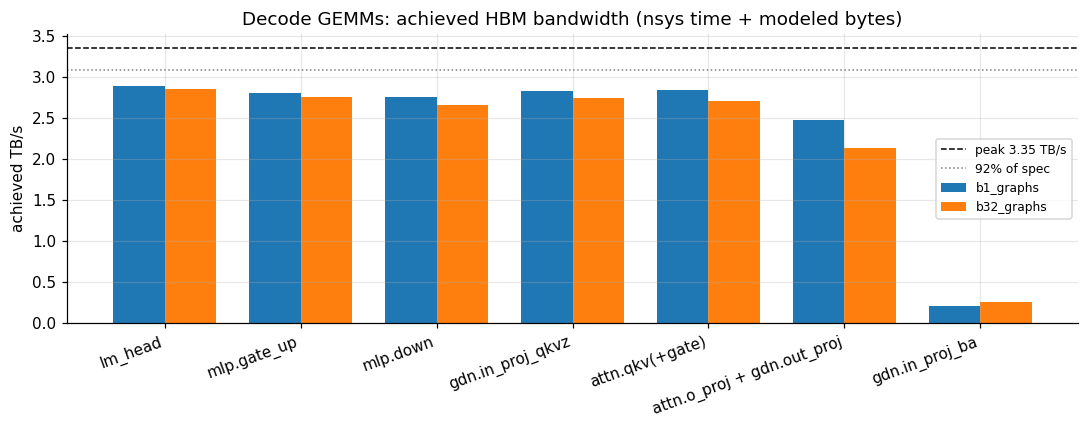

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
w = 0.38
for i, key in enumerate([k for k in ("b1_graphs", "b32_graphs") if k in GA]):
    a = GA[key].dropna(subset=["gemm"]).set_index("gemm")
    order = groups.sort_values("MB_each", ascending=False).gemm
    a = a.reindex([g for g in order if g in a.index])
    ax.bar(np.arange(len(a)) + i * w, a.TBps, w, label=key)
    ax.set_xticks(np.arange(len(a)) + w / 2, a.index, rotation=20, ha="right")
ax.axhline(HW["hbm_bw_TBps"], color="k", ls="--", lw=1, label=f"peak {HW['hbm_bw_TBps']:.2f} TB/s")
ax.axhline(HW["hbm_bw_TBps"] * HW["realistic_bw_frac"], color="gray", ls=":", lw=1, label=f"{HW['realistic_bw_frac']:.0%} of spec")
ax.set(ylabel="achieved TB/s", title="Decode GEMMs: achieved HBM bandwidth (nsys time + modeled bytes)"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("C3_gemm_bandwidth"); plt.show()

## C4. Napkin roofline (from nsys + shapes)
A preview of what ncu will measure directly. Points far below the roof are the ncu targets.

saved analysis/C4_roofline_napkin.png


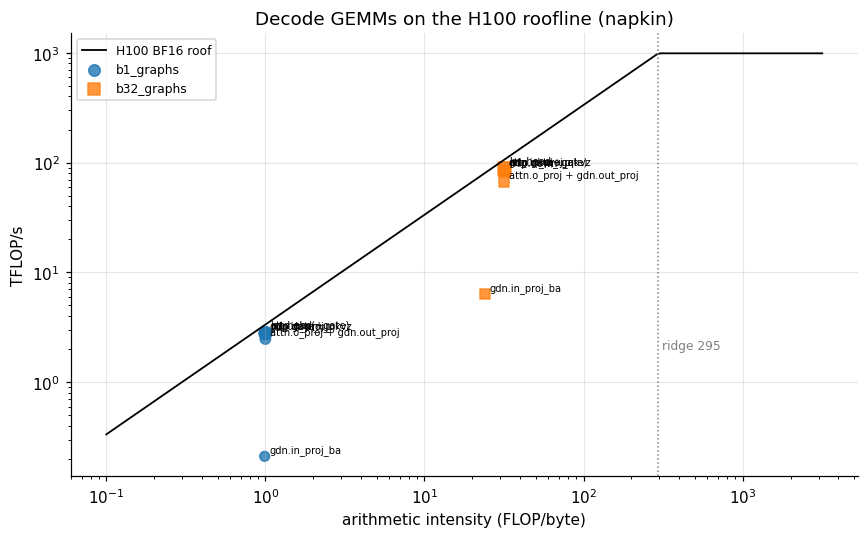

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.logspace(-1, 3.5, 200)
ax.plot(x, np.minimum(x * PEAK_BW, PEAK_FLOPS) / 1e12, "k-", lw=1.2, label="H100 BF16 roof")
mk = {"b1_graphs": "o", "b32_graphs": "s", "b1_eager": "^", "b32_eager": "v"}
for key, a in GA.items():
    if "eager" in key: continue
    a = a.dropna(subset=["gemm"])
    perf = a.GFLOP * 1e9 / (a.avg_us * 1e-6) / 1e12
    ax.scatter(a.AI, perf, marker=mk[key], s=40 + 4 * a.ms_per_step, label=key, alpha=.8)
    for _, r in a.iterrows():
        ax.annotate(r.gemm, (r.AI, r.GFLOP * 1e9 / (r.avg_us * 1e-6) / 1e12), fontsize=6.5, xytext=(3, 3), textcoords="offset points")
ax.axvline(RIDGE, color="gray", ls=":", lw=1); ax.text(RIDGE * 1.05, 2, f"ridge {RIDGE:.0f}", fontsize=8, color="gray")
ax.set(xscale="log", yscale="log", xlabel="arithmetic intensity (FLOP/byte)", ylabel="TFLOP/s", title="Decode GEMMs on the H100 roofline (napkin)")
ax.legend(fontsize=8); plt.tight_layout(); savefig("C4_roofline_napkin"); plt.show()

## C5. Reconciling one decode step (prediction → measurement)
Waterfall: GEMM roofline floor → GEMMs running below peak → non-GEMM kernels → GPU idle → measured step. The bars should add up to the measured step; the gray line is the Part A prediction for comparison.

--- b1_graphs: measured median step 20.68 ms | terms sum to 20.73 ms | Part A whole-step floor 15.40 ms (includes GDN state + KV bytes)


,term,ms,share_%
0,GEMM roofline floor (weights @ 3.35 TB/s),15.301,73.999
1,GEMMs running below peak,3.594,17.381
2,"non-GEMM kernels (GDN, attention, norms, ...)",1.295,6.263
3,GPU idle between kernels,0.539,2.605


saved analysis/C5_waterfall_b1_graphs.png


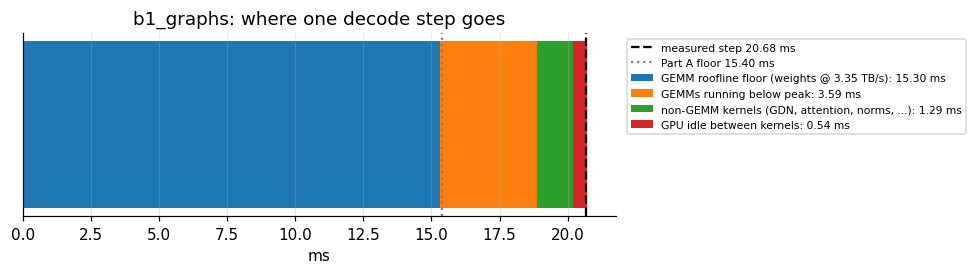

--- b32_graphs: measured median step 25.44 ms | terms sum to 25.47 ms | Part A whole-step floor 18.70 ms (includes GDN state + KV bytes)


,term,ms,share_%
0,GEMM roofline floor (weights @ 3.35 TB/s),15.422,60.612
1,GEMMs running below peak,4.359,17.130
2,"non-GEMM kernels (GDN, attention, norms, ...)",5.130,20.162
3,GPU idle between kernels,0.560,2.201


saved analysis/C5_waterfall_b32_graphs.png


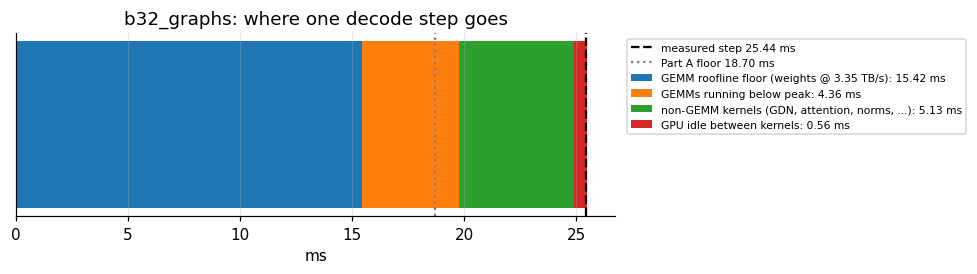

In [17]:
def reconcile(key):
    tr, a, d = TR[key], GA[key], KT[key]["decode"]
    meas = ms(np.median(tr["steps"]))
    gemm_ms = d[d.cat.str.startswith("GEMM")].ms_per_step.sum()
    gemm_floor = (a.floor_us * a.per_step).sum() / 1e3          # GEMM bytes / spec BW
    other = d[~d.cat.str.startswith("GEMM")].ms_per_step.sum()
    idle = PH.loc[key, "decode_idle_per_step_ms"]
    parts = [("GEMM roofline floor (weights @ 3.35 TB/s)", gemm_floor),
             ("GEMMs running below peak", gemm_ms - gemm_floor),
             ("non-GEMM kernels (GDN, attention, norms, ...)", other),
             ("GPU idle between kernels", idle)]
    floor = decode_model(tr["B"], INPUT_LEN + OUT_TOKENS // 2)["t_ms"]
    return pd.DataFrame(parts, columns=["term", "ms"]), meas, floor

for key in [k for k in ("b1_graphs", "b32_graphs") if k in TR]:
    r, meas, floor = reconcile(key)
    r["share_%"] = 100 * r.ms / meas
    print(f"--- {key}: measured median step {meas:.2f} ms | terms sum to {r.ms.sum():.2f} ms | "
          f"Part A whole-step floor {floor:.2f} ms (includes GDN state + KV bytes)")
    display(r.round(3))
    fig, ax = plt.subplots(figsize=(9, 2.6)); left = 0
    for t, v in zip(r.term, r.ms):
        ax.barh(0, v, left=left, label=f"{t}: {v:.2f} ms"); left += v
    ax.axvline(meas, color="k", ls="--", label=f"measured step {meas:.2f} ms")
    ax.axvline(floor, color="gray", ls=":", label=f"Part A floor {floor:.2f} ms")
    ax.set(yticks=[], xlabel="ms", title=f"{key}: where one decode step goes"); ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.tight_layout(); savefig(f"C5_waterfall_{key}"); plt.show()

## C6. CUDA graphs vs eager
Same kernels, different launch mechanism (and in vLLM, eager also disables torch.compile fusion). GEMM times should match; the difference is launch overhead plus unfused small kernels.

In [18]:
rows = []
for B in (1, 32):
    g, e = f"b{B}_graphs", f"b{B}_eager"
    if g in TR and e in TR:
        for metric in ["step_median_ms", "decode_busy_pct", "decode_idle_per_step_ms", "kernels_per_step",
                       "kernel_launches_per_step", "graph_launches_per_step", "prefill_gpu_ms", "prefill_busy_pct"]:
            if metric in PH:
                rows.append(dict(B=B, metric=metric, graphs=float(PH.loc[g, metric]), eager=float(PH.loc[e, metric])))
        ga = KT[g]["decode"]; ea = KT[e]["decode"]
        rows.append(dict(B=B, metric="GEMM ms/step", graphs=ga[ga.cat == "GEMM"].ms_per_step.sum(), eager=ea[ea.cat == "GEMM"].ms_per_step.sum()))
        rows.append(dict(B=B, metric="non-GEMM ms/step", graphs=ga[ga.cat != "GEMM"].ms_per_step.sum(), eager=ea[ea.cat != "GEMM"].ms_per_step.sum()))
GE = pd.DataFrame(rows)
if len(GE):
    GE["eager/graphs"] = GE.eager / GE.graphs.replace(0, np.nan)
    GE.to_csv(OUT_DIR / "C6_graphs_vs_eager.csv", index=False); display(GE.round(2))

,B,metric,graphs,eager,eager/graphs
0,1,step_median_ms,20.68,60.54,2.93
1,1,decode_busy_pct,97.40,38.37,0.39
2,1,decode_idle_per_step_ms,0.54,37.58,69.76
3,1,kernels_per_step,902.00,2464.00,2.73
4,1,kernel_launches_per_step,20.95,2463.95,117.60
5,1,graph_launches_per_step,1.00,0.00,0.00
6,1,prefill_gpu_ms,44.97,53.86,1.20
7,1,prefill_busy_pct,81.93,57.88,0.71
8,1,GEMM ms/step,18.70,18.86,1.01
9,1,non-GEMM ms/step,1.49,4.58,3.07


saved analysis/C6_gaps_busy.png


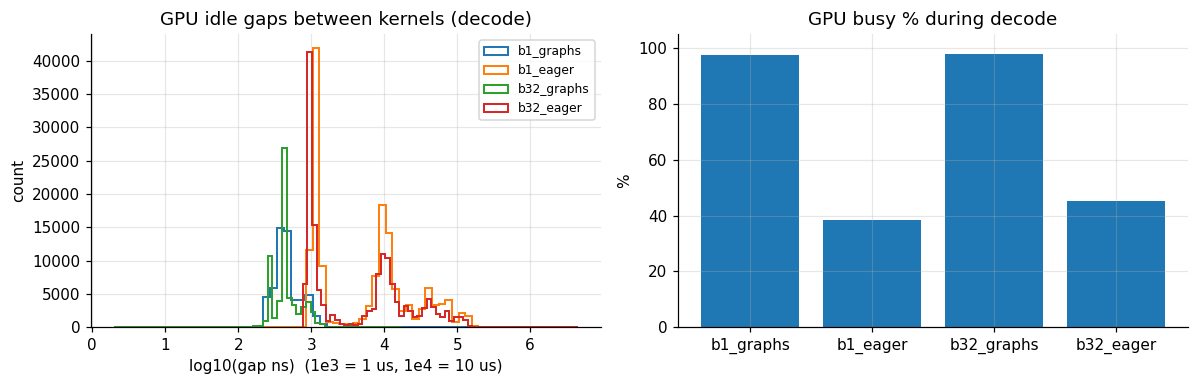

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for key, tr in TR.items():
    g = tr["gaps_dec"]
    if len(g): ax[0].hist(np.log10(g + 1), bins=60, histtype="step", label=key, lw=1.3)
ax[0].set(xlabel="log10(gap ns)  (1e3 = 1 us, 1e4 = 10 us)", ylabel="count", title="GPU idle gaps between kernels (decode)"); ax[0].legend(fontsize=8)
keys = list(TR); ax[1].bar(keys, [PH.loc[k, "decode_busy_pct"] for k in keys])
ax[1].set(ylabel="%", ylim=(0, 105), title="GPU busy % during decode")
plt.tight_layout(); savefig("C6_gaps_busy"); plt.show()

## C7. Auto-generated findings (numbers come from the cells above)

In [20]:
F = []
if "b1_graphs" in TR:
    p = PH.loc["b1_graphs"]; a = GA["b1_graphs"]; d = KT["b1_graphs"]["decode"]
    gshare = 100 * d[d.cat.str.startswith("GEMM")].ms_per_step.sum() / d.ms_per_step.sum()
    am = a.dropna(subset=["gemm"])
    gbw = (am.bytes_MB * am.per_step).sum() / (am.avg_us * am.per_step).sum()   # MB/us = TB/s
    F.append(f"B=1 decode step: {p.step_median_ms:.2f} ms measured vs {PRED['floor_ms']:.2f} ms predicted floor ({p.step_median_ms/PRED['floor_ms']:.2f}x); step-to-step CV {p.step_cv_pct:.1f}%.")
    F.append(f"GEMMs are {gshare:.0f}% of decode kernel time and stream weights at {gbw:.2f} TB/s on average ({100*gbw/HW['hbm_bw_TBps']:.0f}% of spec).")
    F.append(f"GPU is busy {p.decode_busy_pct:.1f}% of decode; idle {p.decode_idle_per_step_ms*1e3:.0f} us per step -> host work is (almost) fully overlapped.")
    F.append(f"Prefill ({INPUT_LEN} tokens): {p.prefill_gpu_ms:.1f} ms of GPU time, GPU busy {p.prefill_busy_pct:.0f}% (piecewise graphs leave GDN/attention ops eagerly launched).")
    if "first_prefill_range_ms" in p:
        F.append(f"First prefill-only call: {p.first_prefill_range_ms:.0f} ms wall vs {p.first_prefill_gpu_ms:.0f} ms GPU -> {p.first_prefill_range_ms-p.first_prefill_gpu_ms:.0f} ms of host-side time (open question).")
    worst = a.dropna(subset=["gemm"]).sort_values("pct_peak_bw").iloc[0]
    F.append(f"Lowest-bandwidth GEMM: {worst.gemm} at {worst.TBps:.2f} TB/s ({worst.avg_us:.1f} us for {worst.bytes_MB:.1f} MB) -> latency-bound, not bandwidth-bound.")
if "b1_eager" in TR and "b1_graphs" in TR:
    F.append(f"Eager vs graphs at B=1: {PH.loc['b1_eager','step_median_ms']:.1f} vs {PH.loc['b1_graphs','step_median_ms']:.1f} ms per step "
             f"({PH.loc['b1_eager','step_median_ms']/PH.loc['b1_graphs','step_median_ms']:.1f}x); GPU busy {PH.loc['b1_eager','decode_busy_pct']:.0f}% vs {PH.loc['b1_graphs','decode_busy_pct']:.0f}%.")
if "b32_graphs" in TR and "b1_graphs" in TR:
    r = PH.loc["b32_graphs", "step_median_ms"] / PH.loc["b1_graphs", "step_median_ms"]
    F.append(f"B=32 step is {r:.2f}x the B=1 step for 32x the tokens -> {32/r:.1f}x throughput; predicted state traffic at B=32 = {decode_model(32, ctx_mid)['state_GB']:.1f} GB/step.")
(OUT_DIR / "findings.md").write_text("\n".join(f"- {f}" for f in F))
print("\n".join(f"- {f}" for f in F))

- B=1 decode step: 20.68 ms measured vs 15.40 ms predicted floor (1.34x); step-to-step CV 1.4%.
- GEMMs are 94% of decode kernel time and stream weights at 2.74 TB/s on average (82% of spec).
- GPU is busy 97.4% of decode; idle 539 us per step -> host work is (almost) fully overlapped.
- Prefill (512 tokens): 45.0 ms of GPU time, GPU busy 82% (piecewise graphs leave GDN/attention ops eagerly launched).
- First prefill-only call: 230 ms wall vs 45 ms GPU -> 185 ms of host-side time (open question).
- Lowest-bandwidth GEMM: gdn.in_proj_ba at 0.21 TB/s (4.7 us for 1.0 MB) -> latency-bound, not bandwidth-bound.
- Eager vs graphs at B=1: 60.5 vs 20.7 ms per step (2.9x); GPU busy 38% vs 97%.
- B=32 step is 1.23x the B=1 step for 32x the tokens -> 26.0x throughput; predicted state traffic at B=32 = 9.9 GB/step.


# Part D. Nsight Compute plan
Kernels are ranked by **time lost per decode step versus their own roofline floor** (GEMMs) or by **time per step** (non-GEMM kernels, which have no byte model here). For each target the cell computes `--launch-skip` from the trace so ncu lands on a steady-state **decode** instance, and writes the commands.

All commands profile the **production configuration** (CUDA graphs + torch.compile) with `--graph-profiling node`, and use `GMU=0.72` so ncu has free GPU memory for its replays.

In [21]:
N_GEMM_TARGETS, N_OTHER_TARGETS = 5, 4
NCU_OUT_TOKENS = 8            # short run: prefill + 7 decode steps
SKIP_DECODE_STEPS = 2         # skip the first decode steps (pipeline fill)

def first_decode_index(tr, name, out_tokens):
    # instances of `name` before decode starts in a prof_run.py capture: prefill_b range + prefill of the decode range
    k = tr["k"]; ends = tr["lm_ends"]
    try:
        ps, pe = nvtx_range(tr, PREFILL_RANGE_PREFIX); n_pre1 = len(clip(k[k.name == name], ps, pe))
    except ValueError: n_pre1 = 0
    n_pre2 = len(clip(k[k.name == name], tr["range"][0], ends[0]))
    return n_pre1 + n_pre2

targets = []
for key in [k for k in ("b1_graphs", "b32_graphs") if k in TR]:
    tr, a, d = TR[key], GA[key], KT[key]["decode"]
    g = a.dropna(subset=["gemm"]).sort_values("lost_us_per_step", ascending=False).head(N_GEMM_TARGETS)
    o = d[~d.cat.str.startswith("GEMM")].sort_values("ms_per_step", ascending=False).head(N_OTHER_TARGETS)
    for kind, df in (("GEMM", g), ("non-GEMM", o)):
        for _, r in df.iterrows():
            skip = first_decode_index(tr, r["name"], NCU_OUT_TOKENS) + int(round(r.per_step)) * SKIP_DECODE_STEPS
            targets.append(dict(trace=key, B=tr["B"], kind=kind, kernel=r["name"], role=r.get("gemm", r.get("cat")),
                                per_step=r.per_step, avg_us=r.avg_us, ms_per_step=r.ms_per_step,
                                lost_us_per_step=r.get("lost_us_per_step", np.nan), pct_peak_bw=r.get("pct_peak_bw", np.nan),
                                launch_skip=skip))
T = pd.DataFrame(targets).drop_duplicates(["B", "kernel"])
T["tag"] = [f"b{b}_{i:02d}_" + re.sub(r"[^A-Za-z0-9]+", "_", str(role))[:24] for i, (b, role) in enumerate(zip(T.B, T.role))]
T.to_csv(NCU_DIR / "ncu_targets.csv", index=False)
display(T.drop(columns=["tag"]).round(2))

,trace,B,kind,kernel,role,per_step,avg_us,ms_per_step,lost_us_per_step,pct_peak_bw,launch_skip
0,b1_graphs,1,GEMM,nvjet_sm90_tst_384x8_64x4_4x1_v_bz_TNT,mlp.gate_up,64.0,127.33,8.15,1336.42,83.60,128
1,b1_graphs,1,GEMM,nvjet_sm90_tst_128x8_64x12_4x1_v_bz_splitK_TNT,mlp.down,64.0,64.64,4.14,730.89,82.33,128
2,b1_graphs,1,GEMM,nvjet_sm90_tst_128x8_64x12_2x1_v_bz_TNT,gdn.in_proj_qkvz,48.0,59.44,2.85,448.72,84.27,96
3,b1_graphs,1,GEMM,nvjet_sm90_tst_64x8_64x16_4x1_v_bz_TNT,attn.o_proj + gdn.out_proj,64.0,25.42,1.63,424.67,73.90,128
4,b1_graphs,1,GEMM,nvjet_sm90_tst_64x8_64x16_2x1_v_bz_splitK_TNT,gdn.in_proj_ba,48.0,4.65,0.22,209.02,6.38,96
5,b1_graphs,1,non-GEMM,fused_recurrent_gated_delta_rule_packed_decode_kernel,GDN recurrent,48.0,5.66,0.27,NaN,NaN,96
6,b1_graphs,1,non-GEMM,triton_red_fused__to_copy_add_fused_add_rms_norm_2,Norm,48.0,3.02,0.14,NaN,NaN,192
7,b1_graphs,1,non-GEMM,cutlass::device_kernel<flash::enable_sm90_or_later<flash::FlashAttnFwdSm90<f...,Full attention,16.0,8.80,0.14,NaN,NaN,64
8,b1_graphs,1,non-GEMM,triton_red_fused__to_copy_add_fused_add_rms_norm_0,Norm,48.0,2.87,0.14,NaN,NaN,192
9,b32_graphs,32,GEMM,nvjet_sm90_tst_384x32_64x4_4x1_v_bz_TNT,mlp.gate_up,64.0,130.33,8.34,1481.06,82.24,128


In [22]:
# The script is run on the VM by notebook 01 (stage "ncu") as:  bash ncu_commands.sh <run_dir> <python>
METRICS = ",".join(RUN_CFG.get("ncu", {}).get("metrics", [
    "gpu__time_duration.sum", "dram__bytes_read.sum", "dram__bytes_write.sum",
    "dram__throughput.avg.pct_of_peak_sustained_elapsed", "sm__throughput.avg.pct_of_peak_sustained_elapsed",
    "launch__grid_size"]))
GMU, MNS = RUN_CFG.get("ncu", {}).get("gmu", 0.72), RUN_CFG.get("ncu", {}).get("mns", 64)
# B=1 profiles run vLLM at the lower ncu memory limit (more free memory for kernel replay). At that limit only
# ~24 GDN recurrent states fit, so a B=32 run would decode 24 sequences at a time (different, x24 GEMM kernels).
# Batch>1 profiles therefore use the production gpu_memory_utilization, exactly as in the nsys traces.
def gmu_for(B):
    return GMU if B == 1 else RUN_CFG["vllm"].get("gpu_memory_utilization", 0.92)
LIMIT_MIN = int(RUN_CFG.get("ncu", {}).get("time_limit_min", 0))   # 0 = no limit
L = [
    "#!/bin/bash",
    f"# Generated by notebook 02 from run {RUN_DIR.name}. Runs on the VM from the repo root.",
    "# usage: bash ncu_commands.sh <run_dir> <python>",
    'RUN="$1"; PY="${2:-python}"; CFG="$RUN/config.json"; OUT="$RUN/ncu"; mkdir -p "$OUT"; FAIL=0; LATE=0',
    f"LIMIT_MIN={LIMIT_MIN}   # ncu.time_limit_min in config.json: profiles that don't fit are skipped (0 = no limit)",
    'DEADLINE=$(( $(date +%s) + LIMIT_MIN * 60 ))',
    f'SUDO="sudo -E env PATH=$PATH HOME=$HOME HF_HOME=$HOME/.cache/huggingface VLLM_ENABLE_V1_MULTIPROCESSING=0 MNS={MNS}"',
    "# each run line sets GMU (vLLM gpu_memory_utilization) for its batch size",
    "run() {  # run <name> <ncu args...> <app...> : skips reports that already exist (safe to re-run after preemption)",
    '  local name="$1"; shift; local TO=""',
    '  if [ -s "$OUT/$name.ncu-rep" ]; then echo "[skip] $name"; return; fi',
    '  if [ "$LIMIT_MIN" -gt 0 ]; then',
    '    local left=$(( DEADLINE - $(date +%s) ))',
    '    if [ "$left" -le 120 ]; then echo "[time] $name skipped: ncu time limit reached"; LATE=$((LATE+1)); return; fi',
    '    TO="timeout --signal=INT --kill-after=60 $left"',
    '  fi',
    '  echo "[run ] $name (GMU=$GMU)"; $SUDO GMU=$GMU $TO ncu -o "$OUT/$name" -f "$@"; local rc=$?',
    '  if [ $rc -eq 124 ]; then echo "[time] $name stopped: ncu time limit reached"; $SUDO rm -f "$OUT/$name.ncu-rep"; LATE=$((LATE+1))',
    '  elif [ $rc -ne 0 ]; then echo "[FAIL] $name"; FAIL=$((FAIL+1))',
    '  elif [ ! -s "$OUT/$name.ncu-rep" ]; then echo "[FAIL] $name: no kernel matched (ncu exits 0 but writes no report)"; FAIL=$((FAIL+1)); fi',
    "}",
    "",
]
L += ["", "# 1) Deep dives: full section set on 3 steady-state decode instances of each target"]
for _, r in T.iterrows():
    demangled = any(ch in r.kernel for ch in "<(:")          # name came from the demangled signature
    # demangled names may carry a "void " prefix in ncu, so match them as a substring
    rx = re.escape(r.kernel) if demangled else "^" + re.escape(r.kernel) + "$"
    base = " --kernel-name-base demangled" if demangled else ""
    L.append(f"# {r.role} | {r.per_step:.0f}/step | {r.avg_us:.1f} us | {r.ms_per_step:.2f} ms/step")
    L.append(f"GMU={gmu_for(int(r.B))} run {r.tag} --target-processes all --profile-from-start off --graph-profiling node \\\n"
             f"  --kernel-name regex:'{rx}'{base} --launch-skip {int(r.launch_skip)} --launch-count 3 \\\n"
             f"  --set full --import-source no --clock-control none \\\n"
             f'  "$PY" scripts/prof_run.py --config "$CFG" --batch {int(r.B)} --mode graphs --out {NCU_OUT_TOKENS}')
L += [
    "",
    "# 2) Light sweep: every kernel of a short decode range, metrics only (production config: CUDA graphs).",
    "#    Application replay: the whole program runs once per metric pass. Kernel replay would save and restore",
    "#    ~57 GB of device memory through host RAM for each of the ~8,000 kernels (days instead of ~30 min).",
]
for B in sorted(T.B.unique()):
    L.append(f'GMU={gmu_for(int(B))} run sweep_b{B} --target-processes all --profile-from-start off --graph-profiling node \\\n'
             f'  --replay-mode application --app-replay-mode relaxed \\\n'
             f'  --nvtx --nvtx-include "prefill_decode{NCU_OUT_TOKENS}_b{B}/" --metrics {METRICS} --clock-control none \\\n'
             f'  "$PY" scripts/prof_run.py --config "$CFG" --batch {B} --mode graphs --out {NCU_OUT_TOKENS}')
L += ["", 'sudo chown -R "$USER" "$OUT"',
      'echo "ncu plan finished with $FAIL failure(s), $LATE skipped for the time limit"', "exit $FAIL"]
(NCU_DIR / "ncu_commands.sh").write_text("\n".join(L) + "\n")
print((NCU_DIR / "ncu_commands.sh").read_text()[:2500], "\n...")
print(f"\nWrote {NCU_DIR.relative_to(REPO)}/ncu_commands.sh ({len(T)} deep dives). "
      f"Notebook 01 uploads and runs it when you run the ncu stage with RUN_ID = '{RUN_DIR.name}'.")

#!/bin/bash
# Generated by notebook 02 from run 2026-10-09_qwen3.8-27b_bf16_initial. Runs on the VM from the repo root.
# usage: bash ncu_commands.sh <run_dir> <python>
RUN="$1"; PY="${2:-python}"; CFG="$RUN/config.json"; OUT="$RUN/ncu"; mkdir -p "$OUT"; FAIL=0; LATE=0
LIMIT_MIN=0   # ncu.time_limit_min in config.json: profiles that don't fit are skipped (0 = no limit)
DEADLINE=$(( $(date +%s) + LIMIT_MIN * 60 ))
SUDO="sudo -E env PATH=$PATH HOME=$HOME HF_HOME=$HOME/.cache/huggingface VLLM_ENABLE_V1_MULTIPROCESSING=0 MNS=64"
# each run line sets GMU (vLLM gpu_memory_utilization) for its batch size
run() {  # run <name> <ncu args...> <app...> : skips reports that already exist (safe to re-run after preemption)
  local name="$1"; shift; local TO=""
  if [ -s "$OUT/$name.ncu-rep" ]; then echo "[skip] $name"; return; fi
  if [ "$LIMIT_MIN" -gt 0 ]; then
    local left=$(( DEADLINE - $(date +%s) ))
    if [ "$left" -le 120 ]; then echo "[time] $name skipped: ncu time limit reached"; LATE=$(

## What to check in ncu for each target
| Target type | Section | Question it answers |
|---|---|---|
| Big decode GEMMs (gate_up, down, qkvz, LM head) | GPU Speed Of Light, Memory Workload Analysis | DRAM throughput vs 3.35 TB/s; is anything other than DRAM (L2, issue) limiting? |
| Small GEMMs (in_proj_ba, o_proj/out_proj) | Launch Statistics, Occupancy | Grid size vs 132 SMs; is it latency-bound (too few CTAs, too little work)? |
| Split-K reduce | Launch Statistics | Cost of splitting K for skinny GEMMs |
| GDN recurrent decode | Memory Workload Analysis | State bytes read+written vs the A2 model (~2 x 3.1 MB per layer per sequence) |
| FlashAttention decode | Speed Of Light | KV bytes vs context length; occupancy at batch 1 |
| Fused RMSNorm (Triton) | Speed Of Light | Pure bandwidth kernel: how close to peak at a few KB? (latency floor) |

After the ncu stage, notebook 01 pulls `runs/<id>/ncu/` (reports + CSV) to the Mac. Open the `.ncu-rep` files in Nsight Compute; the next step is an ncu-analysis notebook that replaces the modeled bytes in C3 with measured `dram__bytes_read.sum`.